# Part 3 walkthrough: Machine Learning and AI for I-94 traffic

**Author:** Kyi Htoo Aung | Smart City Traffic Intelligence Capstone

This notebook presents the results of every Part 3 task. The heavy lifting is done by the scripts next to this notebook (`python notebooks/run_part3.py` rebuilds everything); this notebook loads their saved outputs, shows the figures, and runs live demos of the recommender, the API and the MLflow registry.

> **Accident data:** no real accident dataset was sourced. The classification task uses the brief's **documented proxy label** `high_risk` (High/Severe congestion during severe or low-visibility weather). It demonstrates the workflow and **must not be read as a prediction of actual accidents**.

In [1]:
import json, logging, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

PART3 = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(PART3), str(PART3 / "notebooks")]
logging.basicConfig(level=logging.WARNING)   # notebook: show only warnings and errors
import common
R = common.RESULTS_DIR                     # notebooks/outputs
fig = lambda name: display(Image(filename=str(R / name), width=900))
df = common.load_modelling_data()
train, test = common.time_split(df)
print(f"Modelling rows: {len(df):,} | train 2012-2016: {len(train):,} | test 2017-2018: {len(test):,}")
print(f"Proxy high_risk rate: {df['high_risk'].mean():.1%} | features used by both models: {len(common.FEATURES)}")

Modelling rows: 40,543 | train 2012-2016: 25,297 | test 2017-2018: 15,246
Proxy high_risk rate: 7.7% | features used by both models: 31


## Task 1: Supervised models (shared feature set, chronological test on 2017-2018)

In [2]:
sup = json.loads((R / "supervised_results.json").read_text())
cols_r = ["version", "algorithm", "MAE", "R2", "RMSE", "train_seconds", "model_size_mb"]
cols_c = ["version", "algorithm", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "risky_weather_roc_auc"]
display(Markdown("**Regression: traffic_volume**"), pd.DataFrame(sup["regression"])[cols_r].round(3))
display(Markdown("**Classification: proxy high_risk**"), pd.DataFrame(sup["classification"])[cols_c].round(3))
print("Champions:", sup["champions"])

**Regression: traffic_volume**

,version,algorithm,MAE,R2,RMSE,train_seconds,model_size_mb
0,1,Ridge,548.953,0.872,707.572,0.060,0.002
1,2,RandomForestRegressor,228.410,0.964,374.022,4.690,4.433
2,3,HistGradientBoostingRegressor,232.914,0.963,379.047,2.547,0.894


**Classification: proxy high_risk**

,version,algorithm,accuracy,precision,recall,f1,roc_auc,pr_auc,risky_weather_roc_auc
0,1,LogisticRegression,0.979,0.817,0.987,0.894,0.998,0.966,0.981
1,2,RandomForestClassifier,0.989,0.899,0.992,0.943,0.998,0.975,0.986
2,3,HistGradientBoostingClassifier,0.991,0.924,0.976,0.949,0.997,0.978,0.985


Champions: {'regression': 'hist_gradient_boosting', 'classification': 'hist_gradient_boosting'}


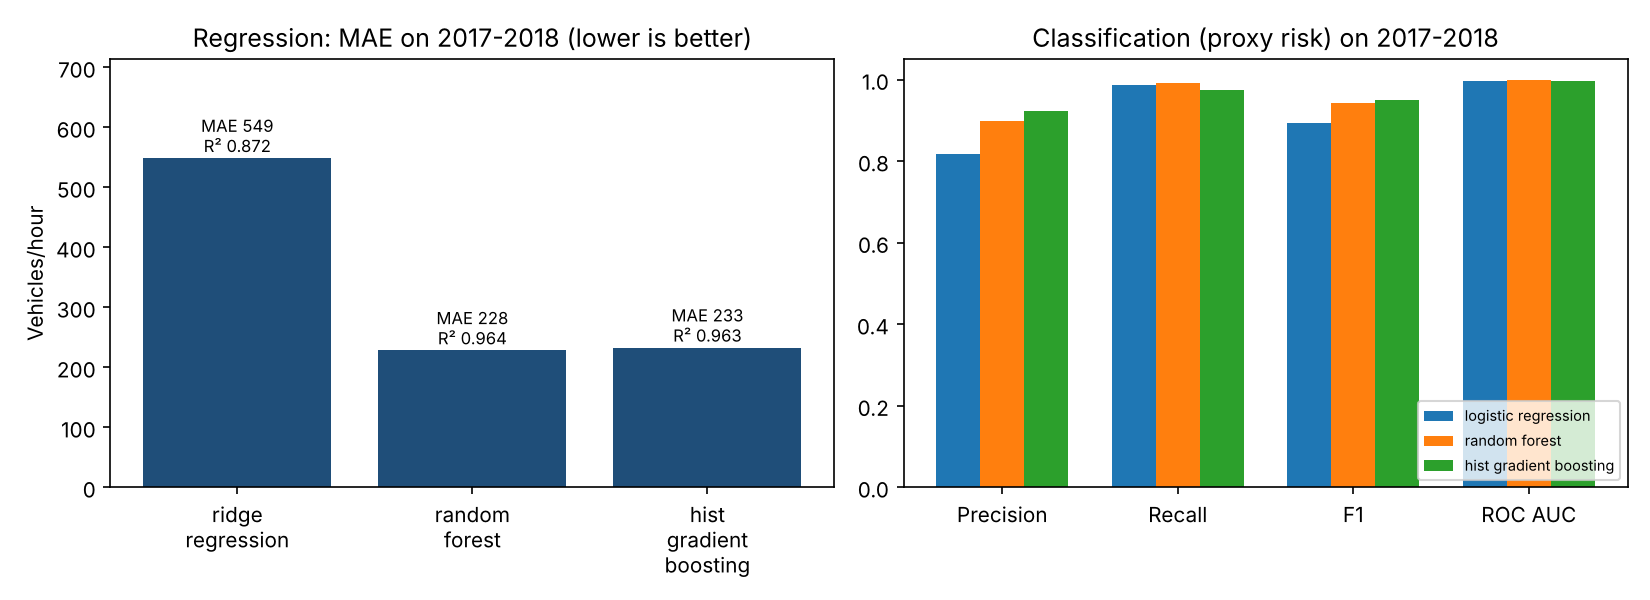

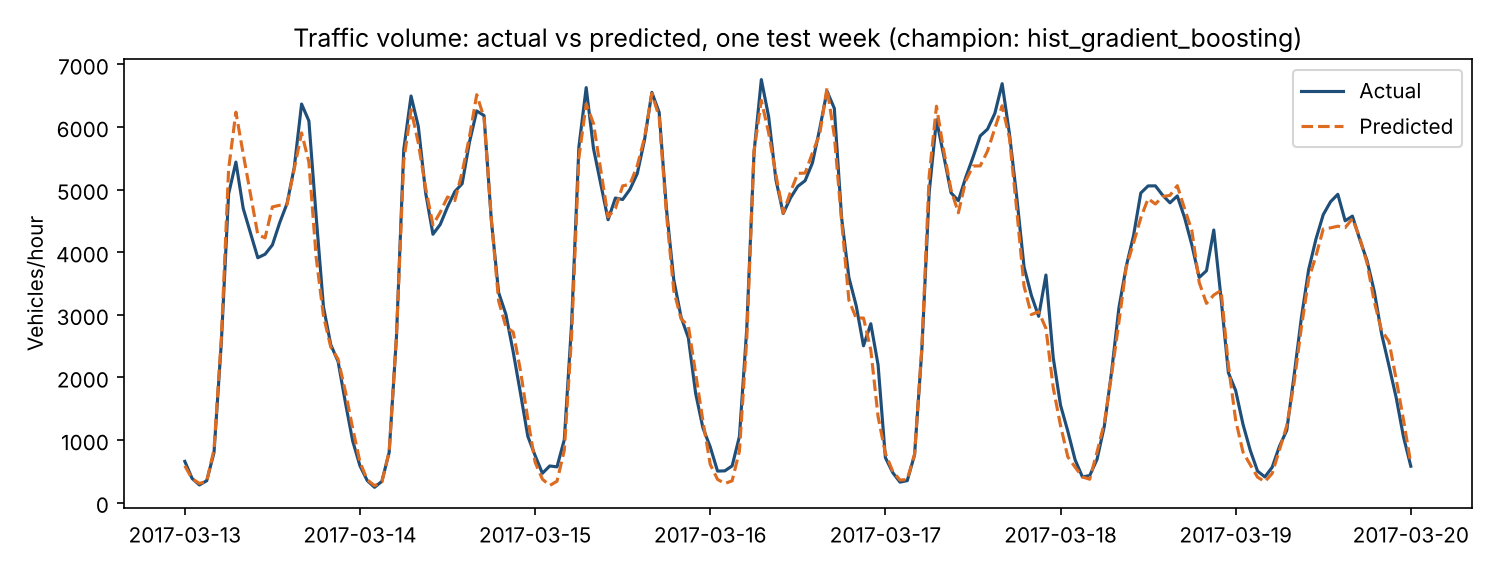

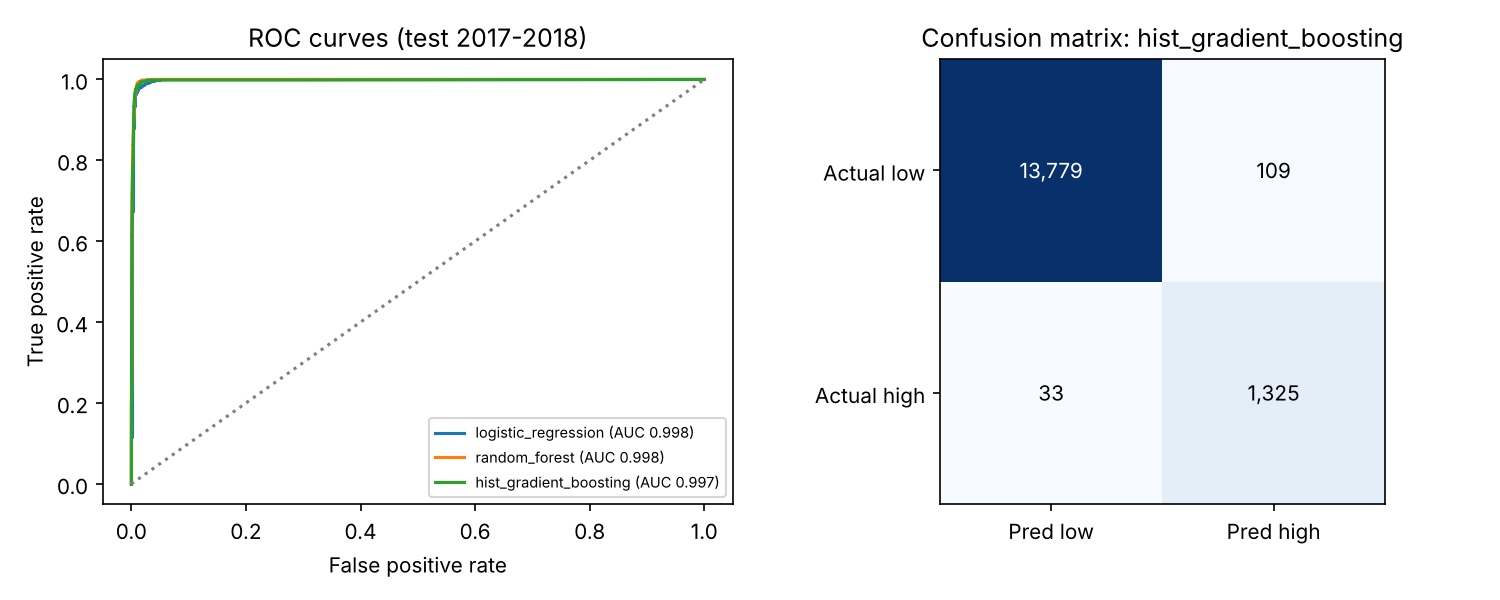

In [3]:
fig("supervised_model_comparison.png"); fig("regression_actual_vs_predicted.png"); fig("classification_roc_confusion.png")

**Reading the classification scores.** The proxy label is built from weather, which is also an input, so the model can rule out every clear-weather hour from the weather inputs alone and the overall scores are inflated. Every positive hour has severe or low-visibility weather and no model raises a false alarm elsewhere, so F1 restricted to those hours is identical to the overall F1 and adds no information. The informative check is ROC AUC within risky-weather hours (`risky_weather_roc_auc`), where the model must genuinely rank congestion: it falls from 0.997 to 0.985 for the champion. This measures congestion prediction in bad weather, not accident risk.

## Task 2: Unsupervised learning

**K-means, k = 8**

,name,hours,share,mean_volume,congested_share,weekend_share,bad_weather_share
0,Quiet weekday 00-05h,5690,0.14,880.11,0.00,0.00,0.00
1,Quiet weekend all day,4790,0.12,1180.08,0.00,1.00,0.11
2,Moderate weekday all day in bad weather,3860,0.10,1556.33,0.00,0.20,0.97
3,Moderate weekday 19-23h,4763,0.12,2548.09,0.00,0.00,0.00
4,Busy weekend 10-20h,5357,0.13,3897.15,0.01,1.00,0.07
5,Peak-congestion weekday 07-17h in bad weather,4165,0.10,4941.58,0.28,0.16,0.98
6,Peak-congestion weekday 06-12h,6339,0.16,5190.48,0.35,0.00,0.00
7,Peak-congestion weekday 13-18h,5579,0.14,5440.40,0.48,0.00,0.00


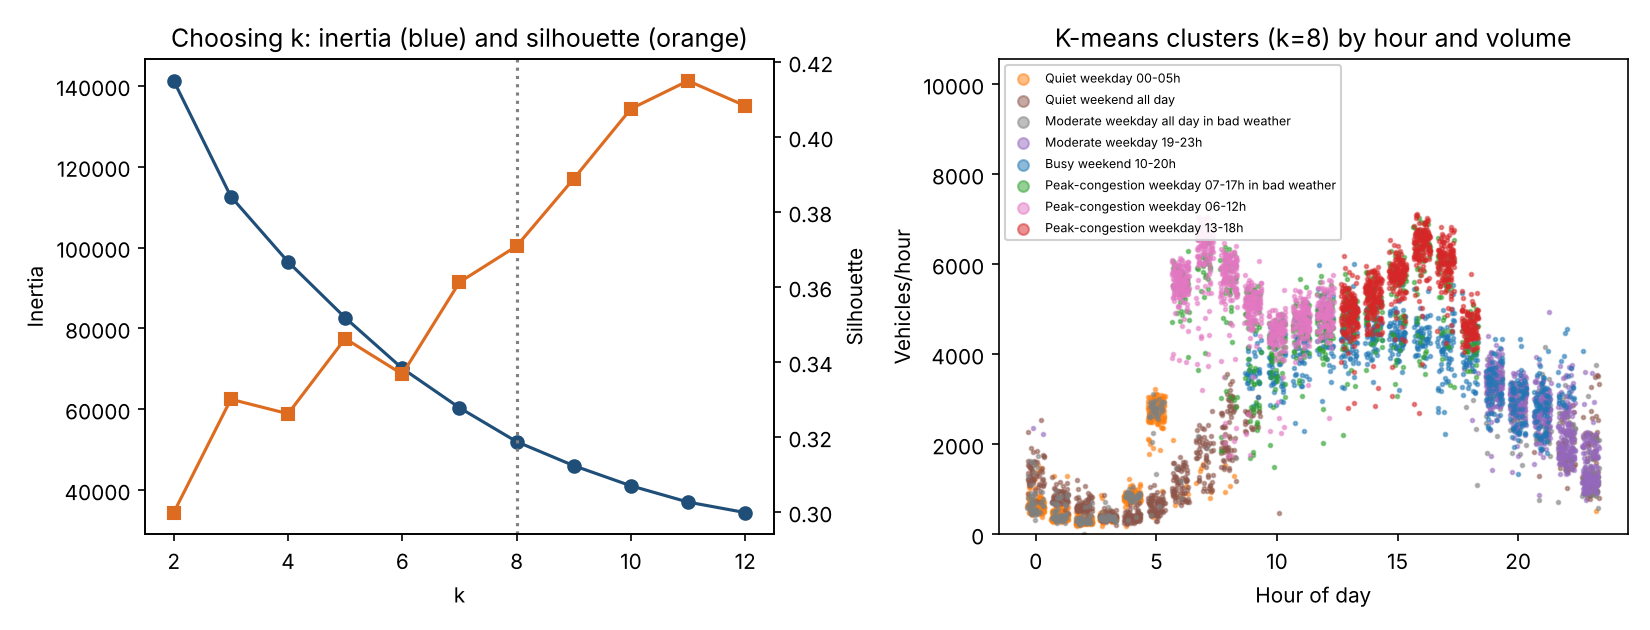

In [4]:
uns = json.loads((R / "unsupervised_results.json").read_text())
clusters = pd.DataFrame(uns["kmeans"]["clusters"])[["name", "hours", "share", "mean_volume", "congested_share", "weekend_share", "bad_weather_share"]]
display(Markdown(f"**K-means, k = {uns['kmeans']['k']}**"), clusters.round(2))
fig("kmeans_clusters.png")

**Top association rules by lift (plain language)**

lift 3.68 | When it is Weekday and Cold and AM peak (06-09), congestion is Severe in 92% of hours, 3.7 times more often than the 25% seen overall.
lift 3.67 | When it is Weekend and Warm and PM peak (15-18), congestion is High in 92% of hours, 3.7 times more often than the 25% seen overall.
lift 3.62 | When it is Weekday and Mild and AM peak (06-09), congestion is Severe in 90% of hours, 3.6 times more often than the 25% seen overall.
lift 3.62 | When it is Weekday and AM peak (06-09) and Low visibility, congestion is Severe in 90% of hours, 3.6 times more often than the 25% seen overall.
lift 3.54 | When it is Weekend and Freezing and Night (23-05), congestion is Low in 88% of hours, 3.5 times more often than the 25% seen overall.
lift 3.54 | When it is Weekday and AM peak (06-09) and Rain/drizzle, congestion is Severe in 88% of hours, 3.5 times more often than the 25% seen overall.
lift 3.52 | When it is Freezing and Evening (19-22), congestion is Medium in 88% of hours, 3.5 times mo

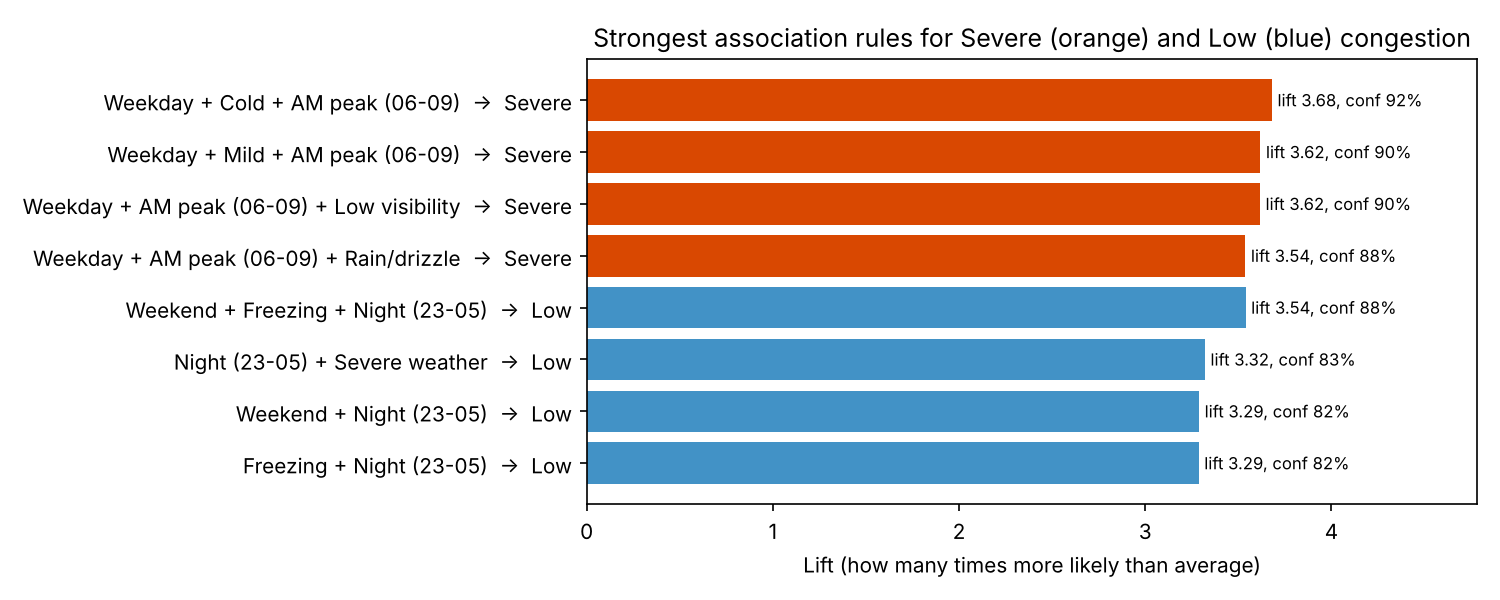

In [5]:
rules = pd.DataFrame(uns["association_rules"]["top_rules"])
display(Markdown("**Top association rules by lift (plain language)**"))
for r in rules.head(8).itertuples():
    print(f"lift {r.lift:.2f} | {r.plain_language}")
fig("association_rules_top.png")

## Task 3: LSTM for next-hour traffic, with explainability

,MAE,R2
LSTM,180.069,0.981
Naive: same as previous hour,592.337,0.826
Naive: same hour yesterday,561.378,0.732
Tree model with lag features (SHAP),153.964,0.986


LSTM: 13,249 parameters, 80 epochs, 42s training, 14,218 train / 14,483 test windows


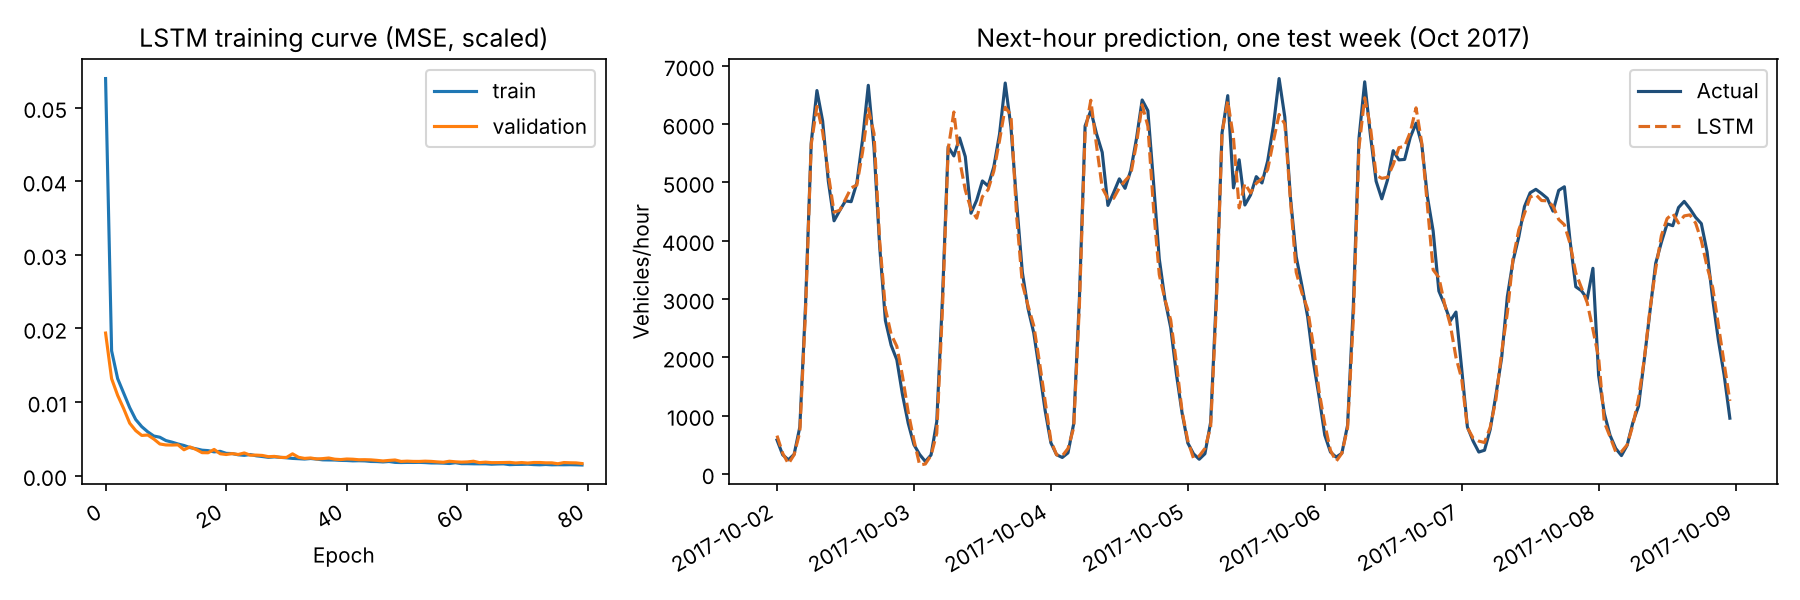

In [6]:
dl = json.loads((R / "deep_learning_results.json").read_text())
display(pd.DataFrame(dl["results"]).T.round(3))
print(f"LSTM: {dl['parameters']:,} parameters, {dl['epochs_run']} epochs, {dl['train_seconds']:.0f}s training, "
      f"{dl['windows']['train']:,} train / {dl['windows']['test']:,} test windows")
fig("lstm_training_and_forecast.png")

**Why SHAP is applied to a tree model:** SHAP is hard to apply reliably to an LSTM, so (as the brief allows) it is applied to a comparable gradient-boosting model trained on the *same* next-hour problem with lag features. The LSTM's own permutation importance below ranks the same signals (recent volume and hour of day) highest, which supports this substitution.

LSTM permutation importance (MAE increase when an input is shuffled):
  target hour: hour_cos            +1,101
  sequence: volume_scaled          +1,010
  sequence: hour_sin               +520
  sequence: hour_cos               +518
  target hour: hour_sin            +508
  target hour: dow_sin             +142


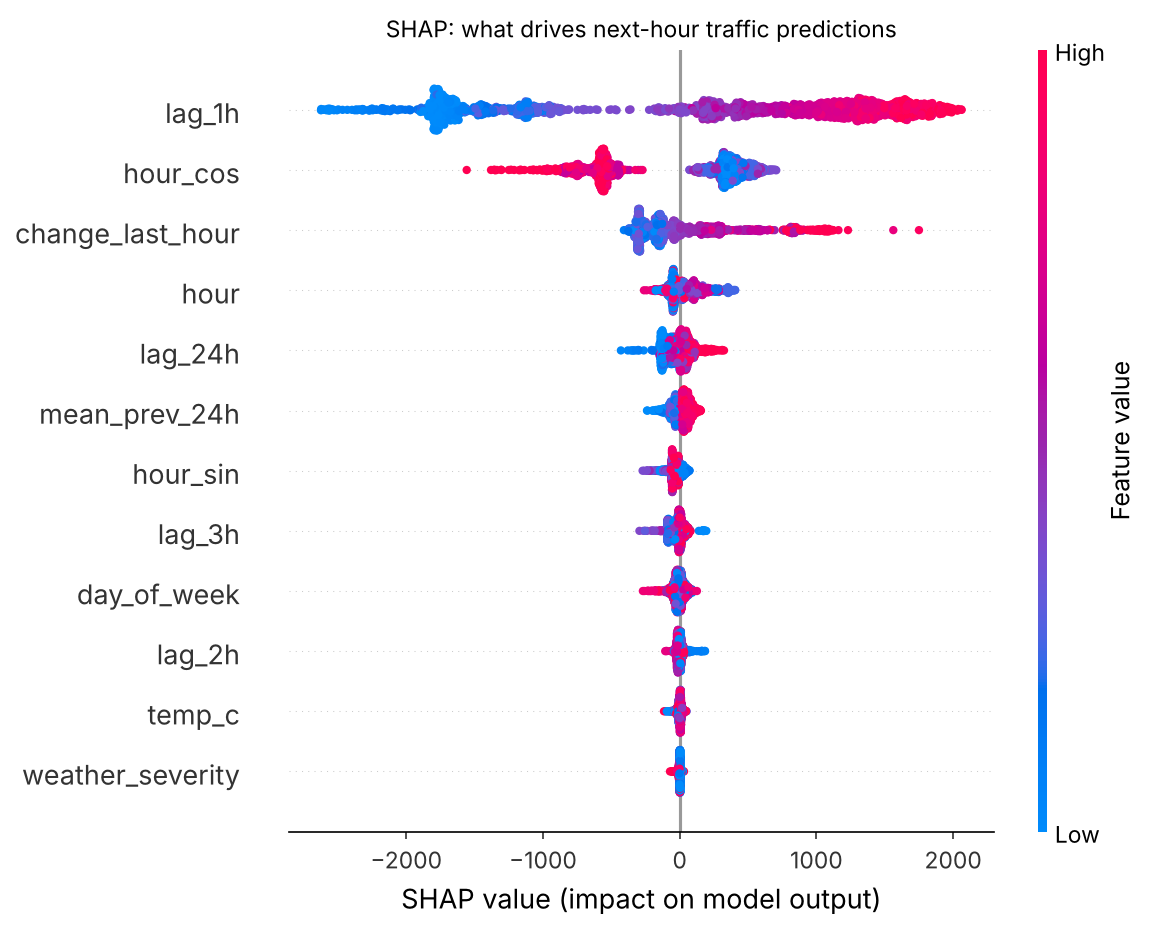

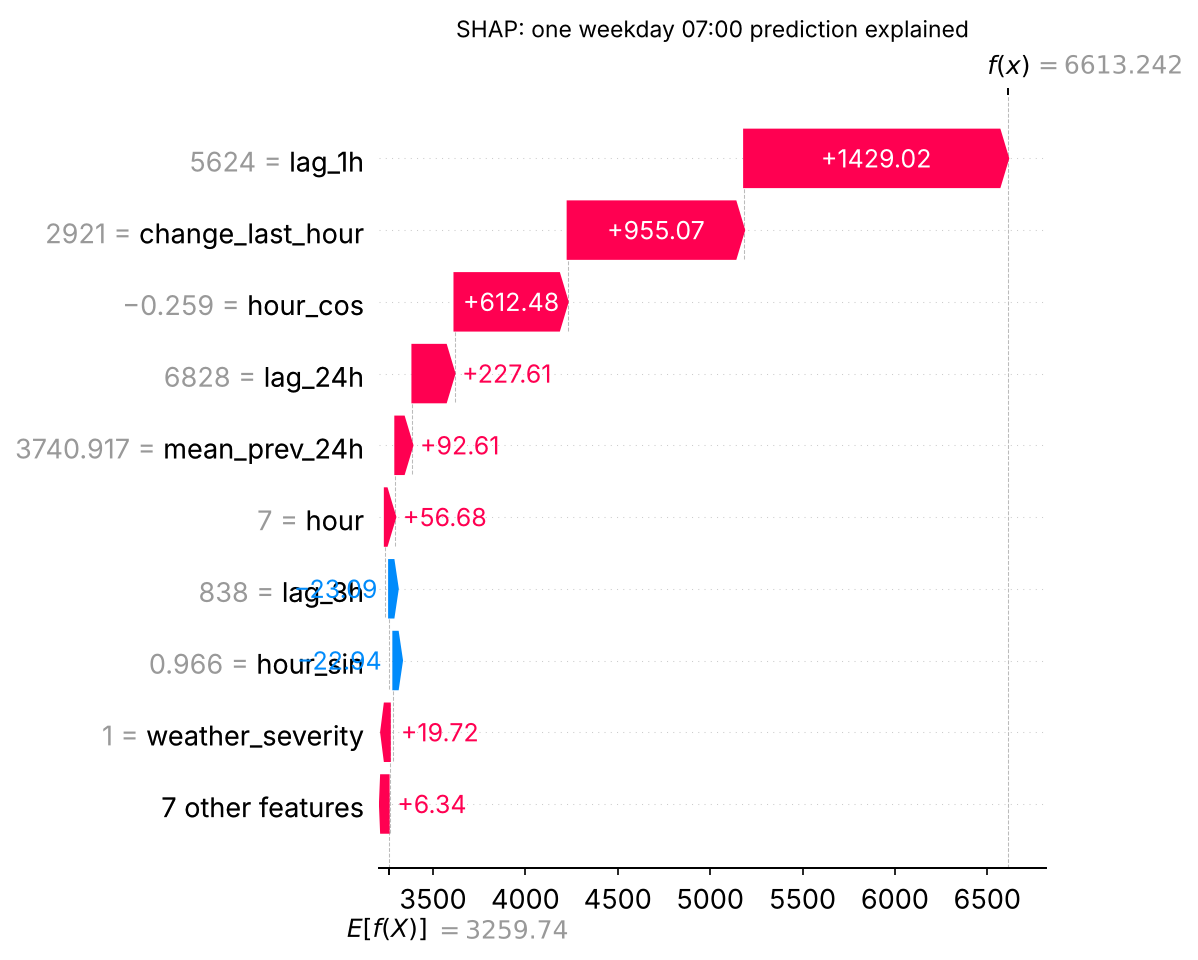

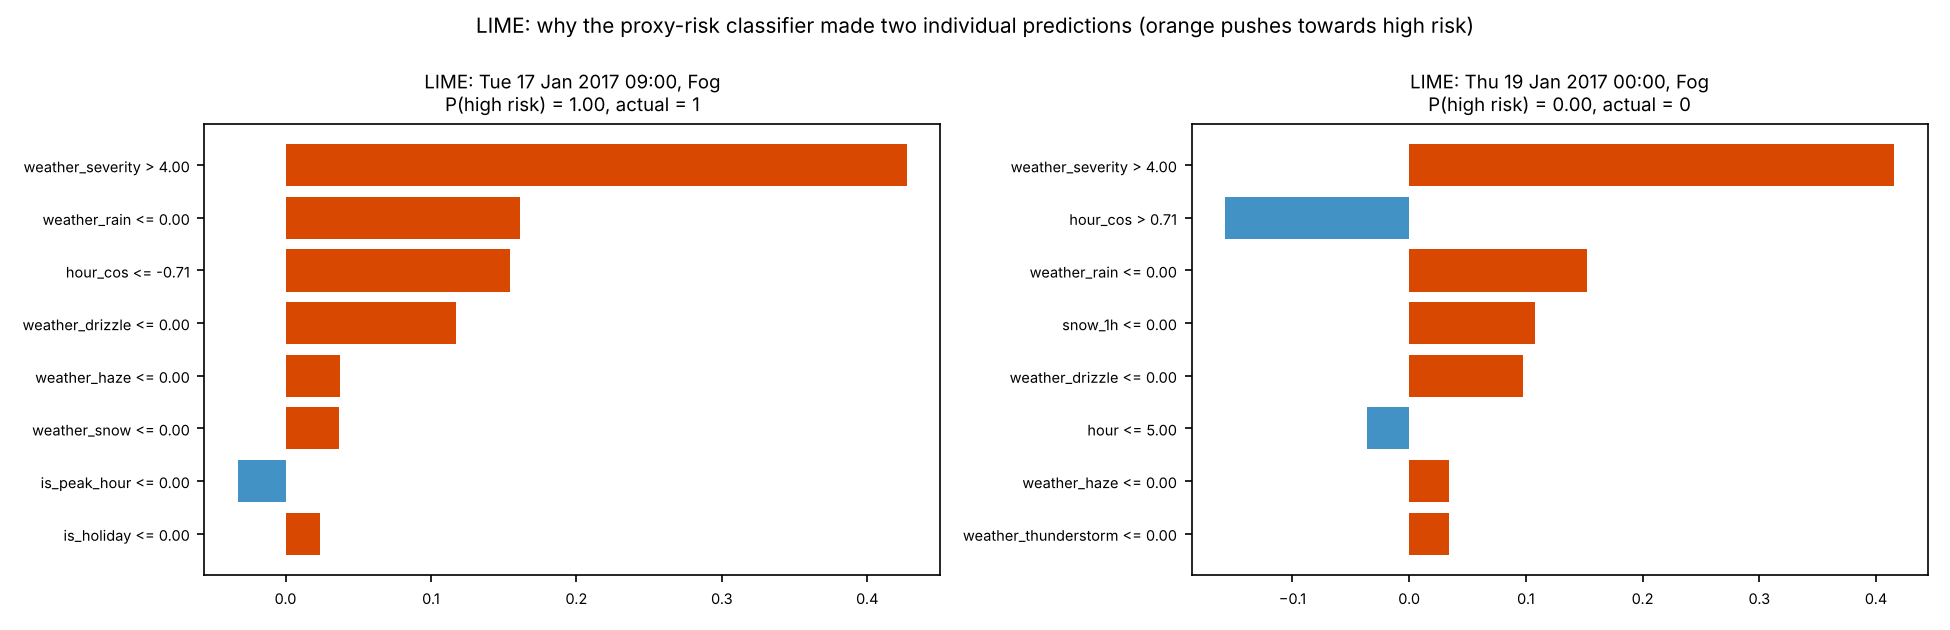

In [7]:
print("LSTM permutation importance (MAE increase when an input is shuffled):")
for k, v in list(dl["lstm_permutation_importance"].items())[:6]:
    print(f"  {k:<32} +{v:,.0f}")
fig("shap_summary_next_hour.png"); fig("shap_waterfall_example.png"); fig("lime_risk_classifier.png")

## Task 4 and 6.1-6.2: MLflow experiment tracking and model registry (live query)

In [8]:
mlflow = common.setup_mlflow("traffic_supervised_models")
client = mlflow.tracking.MlflowClient()
rows = []
for exp in client.search_experiments():
    for run in client.search_runs([exp.experiment_id]):
        rows.append({"experiment": exp.name, "run": run.info.run_name,
                     "metrics": ", ".join(f"{k}={v:.3f}" for k, v in list(run.data.metrics.items())[:4])})
display(pd.DataFrame(rows))
versions = [{"model": mv.name, "version": mv.version, "alias": ", ".join(a for a, v in client.get_registered_model(mv.name).aliases.items() if v == mv.version)}
            for rm in client.search_registered_models() for mv in client.search_model_versions(f"name='{rm.name}'")]
display(pd.DataFrame(versions).sort_values(["model", "version"]))

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,experiment,run,metrics
0,traffic_monitoring,monthly_drift_check_2018,"mae_ratio=0.975, max_psi=2.341"
1,traffic_deep_learning,next_hour_tree_comparable_for_shap,"test_MAE=153.964, test_R2=0.986"
2,traffic_deep_learning,lstm_next_hour_volume,"test_MAE=180.069, test_R2=0.981, train_seconds..."
3,traffic_unsupervised,association_rules_apriori,"n_rules=42.000, top_lift=3.680, top_confidence..."
4,traffic_unsupervised,kmeans_k8,"silhouette=0.371, inertia=51960.425, silhouett..."
5,traffic_supervised_models,classification_hist_gradient_boosting,"accuracy=0.991, precision=0.924, recall=0.976,..."
6,traffic_supervised_models,classification_random_forest,"accuracy=0.989, precision=0.899, recall=0.992,..."
7,traffic_supervised_models,classification_logistic_regression,"accuracy=0.979, precision=0.817, recall=0.987,..."
8,traffic_supervised_models,regression_hist_gradient_boosting,"MAE=232.914, R2=0.963, RMSE=379.047, train_sec..."
9,traffic_supervised_models,regression_random_forest,"MAE=228.410, R2=0.964, RMSE=374.022, train_sec..."


,model,version,alias
2,proxy_risk_classifier,1,
1,proxy_risk_classifier,2,
0,proxy_risk_classifier,3,champion
5,traffic_volume_regressor,1,
4,traffic_volume_regressor,2,
3,traffic_volume_regressor,3,champion


## Task 5: Recommendation system (live)

In [9]:
from recommendation_system.recommender import Request, TravelRecommender
engine = TravelRecommender(history=df)
for req in [Request(day="weekday"), Request(day="Friday", weather="Snow", month=1, earliest=14, latest=20),
            Request(day="weekend", weather="Rain", duration=2)]:
    print("-", engine.recommend(req).message, "\n")

- For a weekday journey, consider travelling between 21:00 and 22:00, when traffic is expected to be around 2,894 vehicles per hour and 0% of comparable past hours were congested. Good alternatives: 19:00 and 20:00; 10:00 and 11:00. Avoid 16:00 and 17:00: traffic is expected to reach about 6,407 vehicles per hour and 94% of comparable past hours were congested, so your recommended window carries about 55% less traffic. 

- For a Friday journey in snow, consider travelling between 20:00 and 21:00, when traffic is expected to be around 2,661 vehicles per hour and 0% of comparable past hours were congested. Good alternatives: 18:00 and 19:00. Avoid 16:00 and 17:00: traffic is expected to reach about 6,014 vehicles per hour and 90% of comparable past hours were congested, so your recommended window carries about 56% less traffic. Snow reduces visibility or grip, so allow extra time and stay clear of the busiest hours, where the proxy risk is highest. 

- For a weekend 2-hour journey in rai

## Task 6.3: Deployment mock-up (FastAPI, called in-process)

In [10]:
from fastapi.testclient import TestClient
from deployment.app import app
api = TestClient(app)
print(api.get("/health").json())
print(api.post("/predict/traffic", json={"datetime": "2018-10-02 08:00", "weather": "Clear", "temp_c": 10}).json())
print(api.post("/predict/risk", json={"datetime": "2018-01-16 07:00", "weather": "Fog", "temp_c": -5}).json())
print(api.post("/predict/traffic", json={"datetime": "not a date", "weather": "Clear", "temp_c": 10}).json())

{'status': 'ok', 'models': {'regression': {'registered_model': 'traffic_volume_regressor', 'version': 3, 'algorithm': 'HistGradientBoostingRegressor'}, 'classification': {'registered_model': 'proxy_risk_classifier', 'version': 3, 'algorithm': 'HistGradientBoostingClassifier'}}}


/usr/local/lib/python3.12/dist-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


{'datetime': '2018-10-02 08:00', 'predicted_volume': 5800, 'congestion_category': 'Severe', 'congested_over_5500': True, 'model': {'registered_model': 'traffic_volume_regressor', 'version': 3, 'algorithm': 'HistGradientBoostingRegressor'}}
{'datetime': '2018-01-16 07:00', 'proxy_risk_probability': 0.991, 'high_risk': True, 'note': 'high_risk is a documented proxy (heavy congestion during severe or low-visibility weather), not a prediction of real accidents', 'model': {'registered_model': 'proxy_risk_classifier', 'version': 3, 'algorithm': 'HistGradientBoostingClassifier'}}
{'detail': "Malformed datetime 'not a date'. Use YYYY-MM-DD HH:MM"}


## Task 6.4-6.5: Monitoring and alerting

Overall status: ALERT / Requires investigation


,batch,status,action,mae,reference_mae,psi_temp_c,psi_weather_main
0,2018-01,PASS,None,313.32,259.20,0.13,0.21
1,2018-02,ALERT,Watch: inputs are unusual but accuracy is with...,261.78,233.18,0.78,0.22
2,2018-03,ALERT,Watch: inputs are unusual but accuracy is with...,226.65,211.35,1.11,0.26
3,2018-04,ALERT,Investigate now: accuracy has degraded,323.94,207.61,0.97,0.61
4,2018-05,ALERT,Watch: inputs are unusual but accuracy is with...,183.97,195.73,0.50,0.14
5,2018-06,ALERT,Watch: inputs are unusual but accuracy is with...,172.55,190.14,0.15,0.14
6,2018-07,PASS,None,213.51,249.98,0.03,0.13
7,2018-08,PASS,None,181.15,202.64,0.17,0.18
8,2018-09,PASS,None,186.35,220.85,0.14,0.19
9,SIM sensor_fault,ALERT,Investigate now: accuracy has degraded,1279.39,220.85,0.14,0.19


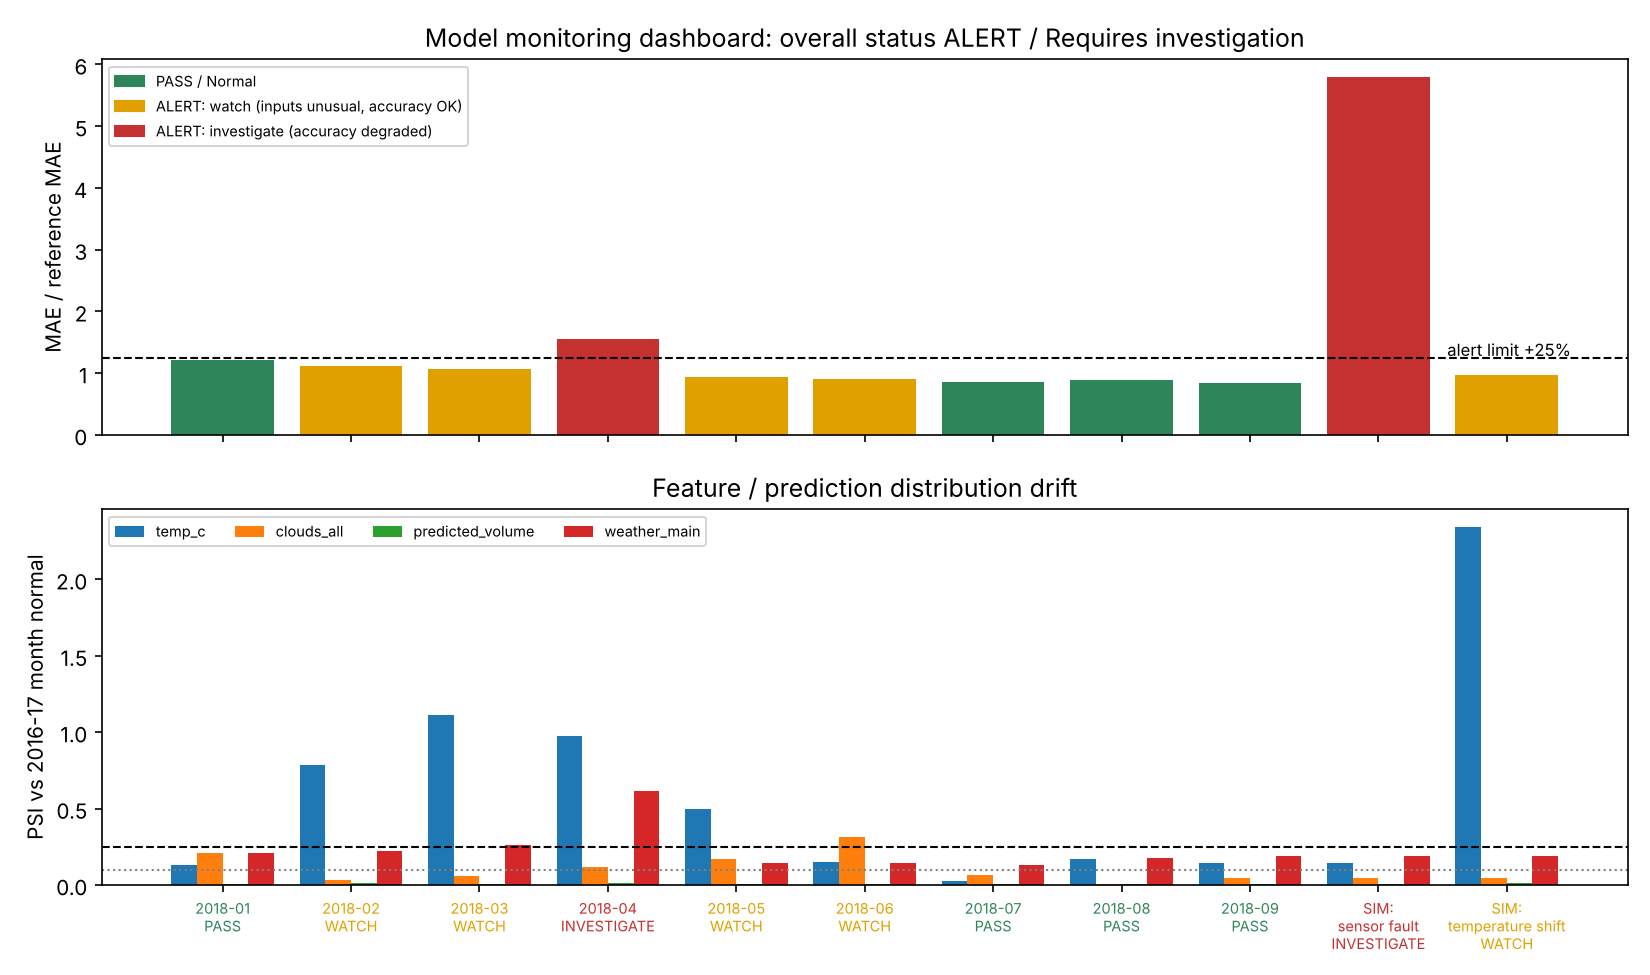

In [11]:
mon = json.loads((PART3 / "monitoring" / "monitoring_status.json").read_text())
print("Overall status:", mon["overall_status"])
display(pd.DataFrame(mon["batches"])[["batch", "status", "action", "mae", "reference_mae", "psi_temp_c", "psi_weather_main"]].round(2))
display(Image(filename=str(PART3 / "monitoring" / "monitoring_dashboard.png"), width=900))

## Task 7: Responsible AI

See `responsible_ai_report.pdf` for the bias and fairness analysis (coverage gaps, proxy-label risks, uneven errors by weather, time and period) and the governance and sustainability discussion. The error breakdown it uses is computed in `notebooks/train_supervised.py`:

In [12]:
eb = sup["error_breakdown"]
for group in ("weather_group", "hour_band", "day_group", "year"):
    display(Markdown(f"**Errors by {group}**"), pd.DataFrame(eb[group]).round(3))

**Errors by weather_group**

,weather_group,hours,MAE,median_pct_error,risk_recall,risk_positives,false_alarm_rate
0,Clear/cloudy,10367,225.059,0.052,NaN,NaN,0.000
1,Low visibility,1407,198.534,0.057,0.973,625.0,0.010
2,Rain/drizzle,1841,196.890,0.049,NaN,NaN,0.000
3,Severe (snow/storm),1631,353.167,0.083,0.978,733.0,0.112


**Errors by hour_band**

,hour_band,hours,MAE,median_pct_error,risk_recall,risk_positives,false_alarm_rate
0,AM peak 6-9,2533,317.371,0.049,0.994,529.0,0.010
1,Evening 20-23,2547,276.254,0.083,0.333,12.0,0.006
2,Midday 10-15,3821,246.384,0.036,0.987,550.0,0.012
3,Night 0-5,3799,90.111,0.082,NaN,NaN,0.000
4,PM peak 16-19,2546,298.400,0.045,0.944,267.0,0.014


**Errors by day_group**

,day_group,hours,MAE,median_pct_error,risk_recall,risk_positives,false_alarm_rate
0,Holiday,431,492.504,0.135,0.978,45,0.054
1,Weekday,10440,204.426,0.044,0.988,1116,0.004
2,Weekend,4375,275.323,0.085,0.909,197,0.012


**Errors by year**

,year,hours,MAE,median_pct_error,risk_recall,risk_positives,false_alarm_rate
0,2017,8713,235.901,0.055,0.976,764,0.004
1,2018,6533,228.932,0.054,0.975,594,0.013
